# Stock-Level Momentum: Construction, Validation and Backtest

## Workflow and scope

1. **Freeze inputs.** Read the authorized WRDS annual CRSP snapshot (December 1925–December 2025), its trading calendar, historical classifications and delisting records. Read KF daily/monthly **value-weighted momentum deciles** independently.
2. **Form monthly portfolios.** Select common stocks on NYSE/AMEX/NASDAQ using formation-date classifications. Rank on months **t−12 through t−2**, skip t−1, apply NYSE decile cutoffs, and weight stocks by t−1 market equity. Require price at t−13, a good t−2 return, and positive t−1 market equity.
3. **Value stocks.** Set missing **ordinary** stock returns to zero under the selected valuation convention. Include known delisting returns once, following DM. Preserve unknown/partial terminal values as unknown. These missing-data choices are distinguished from published construction rules below.
4. **Build returns.** Monthly WML is monthly P10 minus P1. Within a holding month, reconstruct each leg's daily return using drifting stock values and fixed membership, then subtract the two legs. Do not compound daily WML into monthly WML.
5. **Forecast risk.** At month-end, compute $\hat\sigma=\sqrt{21\sum_{j=1}^{126}r_{WML,j}^2/126}$. Apply $(0.12/\sqrt{12})/\hat\sigma$ to the following month's monthly WML. Missing forecasts remain unknown, never cash.
6. **Evaluate identical calendars.** Show available paper-era **1927-05–2011-12** and the disjoint extension **2012–2025**. The original paper starts 1927-03; its first two risk forecasts cannot be reproduced from the available public early daily history.
7. **Report results and checks.** Retain complete KF and published-return stock-reference results, stock transaction costs, monthly reconstruction residuals, and the latest DM-aligned coverage. Withhold full-window independent-stock metrics when valuations are incomplete.

**Interpretation:** The complete stock reference uses published numeric monthly returns with numeric monthly gaps set to zero and **shared KF risk weights**. It isolates monthly WML differences but retains unconfirmed terminal values. The current DM-aligned calculation is stricter about terminal values and remains incomplete. The two are labelled throughout; a complete reference is not evidence of a complete independent replication.

Earlier notebooks and superseded experiments are archived. This notebook contains the current process and the retained results only.

**Current formation-quality update:** require a usable period-end formation value and t−13 price. Reject LA and invalid price/date substitutes; retain valid TR/BA and NS only when the actual price date is period-end. All current monthly tables and shared-KF-risk accounts below use the new universe. Independent stock-daily inputs have been supplemented for changed memberships (10,507 additional daily rows). Strict period/special-value checks still leave no complete month-end 126-session stock-risk forecast; independent managed performance is withheld, not converted into cash. Full label meanings and field-specific policy are in `CIZ_FLAGS.md`.

**Implementation:** all current construction, valuation, daily reconstruction and risk calculations call `src/momentum_risk_project/wml_pipeline.py`. Notebook 05 can load the same versioned build and pass explicit monthly factor weights to its stock-level cost interface. Cached comparison files are validation targets, not a second implementation.

## 1. Sources, documented rules and selected assumptions

- **Raw stock data:** WRDS `crsp_a_stock.msf_v2`, `dsf_v2`, `msenames`, `stkdelists`, `metaexchangecalendar`, and metadata. CRSP is the data provider; WRDS is the access platform. The accessible annual release covers 2025. Query text and file fingerprints are in the local extraction manifest; a coverage end date does not prove release identity with KF.
- **Monthly momentum definition:** [KF monthly momentum deciles](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_port_form_pr_12_2.html). Stock returns in current CIZ are compounded daily **simple total returns**, including dividends; WML is the difference between the two monthly leg returns. [KF CIZ notes](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html).
- **Daily benchmark:** [KF daily momentum deciles](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_port_form_pr_12_2_daily.html). KF forms its daily portfolios daily; our stock daily returns retain monthly membership, as in [DM Section 3.1](https://www.kentdaniel.net/data/momentum/mom_data.pdf). This difference is retained in the interpretation.
- **Delisting:** [DM Section 2, item 6](https://www.kentdaniel.net/data/momentum/mom_data.pdf) includes delisting return on the delisting date. CRSP [aggregate flags](https://www.crsp.org/wp-content/uploads/appendix/FlagType_AR.html) and [delisting flags](https://www.crsp.org/wp-content/uploads/appendix/FlagType_DE.html) distinguish unavailable returns from terminal-payoff completeness. NT does not itself mean delisted.
- **2025 classifications:** Legacy classifications stop at 2024. Map observed CIZ fields using the [CRSP ShareCode table](https://www.crsp.org/wp-content/uploads/ShareCode.html) and [WRDS CIZtoSIZ mapping](https://wrds-www.wharton.upenn.edu/pages/wrds-research/macros/crsp-ciztosiz-macro/). Retain an explicit source label; do not overwrite raw historical codes.
- **Risk scaling:** Barroso–Santa-Clara (2015), [paper](https://www.sciencedirect.com/science/article/pii/S0304405X14002566), Equations 5–6: 126 daily squared returns, 21 sessions per month, no demeaning, next-month execution, 12% annual target.

**Selected conventions, not claimed official rules:** ordinary missing daily/monthly returns are zero; the CIZ NT/MP/missing-price/N adapter identifies permitted intermediate ranking gaps and omits them from the ranking product; exact equivalence to legacy −99 is unproven. Unknown terminal values are not zero. Known late payoffs are attributed to their delisting event for research, not asserted to be cash available at that date. A >200-trading-day price-gap audit adds no otherwise-eligible monthly exclusions here; it is not presented as a documented KF monthly eligibility rule.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/momentum_risk_project").exists())
sys.path.insert(0, str(ROOT / "src"))
from momentum_risk_project.data import clean_momentum
from momentum_risk_project.metrics import performance_metrics
from momentum_risk_project.wml_pipeline import build_from_cache, rebuild_daily, estimate_risk, save_build, load_build

CACHE = ROOT / "data/raw/03_stock_full_20261031"
REFERENCE = ROOT / "data/processed/reference/pre_quality"
CURRENT = ROOT / "outputs/03_wml/validation/checked_daily"
REPORT = ROOT / "outputs/03_wml/report"
API_ARTIFACT = ROOT / "data/processed/wml_current_v1_20261031"
DAILY_CACHE = ROOT / "data/raw/03_quality_daily_20261031"
QUALITY = ROOT / "outputs/03_wml/validation/formation_quality"
AUDIT = ROOT / "outputs/03_wml/diagnostics/august1935"
WINDOWS = {
    "paper_available_common": ("1927-05", "2011-12"),
    "extension_disjoint": ("2012-01", "2025-12"),
}
TARGET_VOL, WINDOW, DAYS_PER_MONTH = 0.12, 126, 21

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""): h.update(block)
    return h.hexdigest()

def read_monthly_csv(path):
    f = pd.read_csv(path, index_col=0)
    f.index = pd.PeriodIndex(f.index, freq="M")
    assert f.index.is_unique and f.index.is_monotonic_increasing
    return f

def display_metrics(frame):
    formats = {c: "{:.2%}" for c in ["Annualized Mean Return", "Annualized Volatility", "CAGR", "Maximum Drawdown", "Mean monthly turnover", "Annual trading cost", "Annual financing cost"] if c in frame}
    formats.update({c: "{:.3f}" for c in ["Sharpe (rf=0)"] if c in frame})
    display(frame.style.format(formats, na_rep="Unavailable"))

source = json.loads((CACHE / "cache_manifest.json").read_text())
current_run = json.loads((CURRENT / "run.json").read_text())
assert source["status"] == "complete"
for name in ["monthly_enriched", "calendar", "delists", "price_gap_intervals"]:
    assert sha256(CACHE / f"{name}.parquet") == source["files"][name]["sha256"]
display(pd.DataFrame([
    {"source": "CRSP annual cache", "start": source["requested_start"], "end": source["requested_end"], "files": len(source["files"])},
    {"source": "CRSP monthly observations", "rows": source["files"]["monthly_enriched"]["rows"]},
    {"source": "Selected-stock daily observations", "rows": sum(v["rows"] for k,v in source["files"].items() if k.startswith("held_daily/"))},
]))

,source,start,end,files,rows
0,CRSP annual cache,1925-12-01,2025-12-31,106.0,NaN
1,CRSP monthly observations,NaN,NaN,NaN,5240606.0
2,Selected-stock daily observations,NaN,NaN,NaN,22463849.0


## 2. Construct and validate monthly holdings

Formation information precedes the holding month. Historical share codes 10/11 and exchange codes 1/2/3 are used where available; 2025 formation observations use the documented CIZ mapping. Already-delisted issues cannot enter a new portfolio. The holding-month return does not determine membership.

NYSE breakpoints assign the decile. Within each decile, `leg_weight = formation market equity / decile market equity`. Each leg sums to one. A WML factor weight of one is +1 winner and −1 loser: gross notional two, net dollar notional zero.

In [2]:
wml_build = build_from_cache(CACHE, start="1927-01", end="2025-12")
holdings = wml_build.holdings
breakpoints, construction_audit = wml_build.breakpoints, wml_build.audit
np.testing.assert_allclose(holdings.groupby(["month", "momentum_decile"]).leg_weight.sum(), 1, atol=1e-12)
assert (holdings.formation_month + 1).equals(holdings.month)
assert holdings.formation_shrcd.isin([10, 11]).all()
assert holdings.formation_exchcd.isin([1, 2, 3]).all()
assert holdings.kf_ranking_valid.all() and holdings.price_t13.gt(0).all()
assert holdings.formation_cap.gt(0).all()
display(pd.Series(construction_audit, name="Value").to_frame())
display(holdings.groupby("eligibility_source").size().rename("Formed stock-months").to_frame())
example = holdings.loc[holdings.month.eq(pd.Period("2009-02"))]
display(example.groupby("momentum_decile").agg(stocks=("permno", "size"),
    formation_equity=("formation_cap", "sum"), weight_sum=("leg_weight", "sum")))

,Value
formation_candidates,3838254
formation_candidates_in_price_gap,9565
formation_price_gap_exclusions,0
eligible_stock_months,3493938
ciz_fallback_eligible_stock_months,39352
admitted_with_missing_price_history,4200
missing_numeric_wml_stock_months,66
formation_policy,period-end TR/BA; NS only on actual period-end...
monthly_policy,ordinary gaps zero; known DM payoff once; unkn...
reference_policy,"published numeric monthly returns, numeric gap..."


,Formed stock-months
eligibility_source,
CIZ post-2024 screen (not exact legacy equivalence),39352
observed historical share/exchange codes,3454586


,stocks,formation_equity,weight_sum
momentum_decile,,,
1,689,1.019365e+08,1.0
2,500,2.692204e+08,1.0
3,349,3.491899e+08,1.0
4,427,5.996934e+08,1.0
5,376,8.365336e+08,1.0
6,347,1.175842e+09,1.0
7,325,1.308213e+09,1.0
8,315,1.403260e+09,1.0
9,382,1.987383e+09,1.0


## 3. Resolve monthly returns and terminal payoffs

Keep the total-return amount and payoff quality separate. Included A/P monthly payoffs stay unchanged; finite excluded G/M payoffs are compounded once. For ordinary returns that are unavailable with no delisting evidence, use the selected zero convention. Missing/partial terminal values remain unknown.

Two labelled monthly series are retained: **current DM-aligned WML**, with unknown terminal payoffs preserved, and the **published-return reference**, which retains numeric published observations even when terminal completeness is unconfirmed and sets its numeric monthly gaps to zero. The latter is the complete reference for the retained backtest tables; it is not promoted to a fully reconciled stock account.

In [3]:
holdings["current_return"] = holdings.return_dm
ordinary = holdings.dm_imputed & holdings.delistingdt.isna()
recorded = holdings.dm_imputed & holdings.delistingdt.notna()
current_monthly = wml_build.monthly_dm
reference_monthly = wml_build.monthly_reference
native = pd.DataFrame({"KF_unmanaged": clean_momentum(pd.read_parquet(ROOT / "data/raw/02_kf_momentum_deciles_monthly_vw.parquet"), "monthly").mom, "reconstructed_DM_unmanaged": current_monthly.WML}).loc["1927-01":"2025-12"]
reference = read_monthly_csv(QUALITY / "monthly_returns.csv").rename(columns={"quality_screened_unmanaged":"reconstructed_unmanaged"})
np.testing.assert_allclose(current_monthly.WML.reindex(native.index), native.reconstructed_DM_unmanaged, equal_nan=True, atol=1e-12)
np.testing.assert_allclose(reference_monthly.WML.reindex(reference.index), reference.reconstructed_unmanaged, atol=1e-12)
recovered = holdings.return_resolution.eq("recorded_excluded_delisting_return_added_once")
np.testing.assert_allclose(holdings.loc[recovered, "return_strict"],
    (1 + holdings.loc[recovered, "mthret"]) * (1 + holdings.loc[recovered, "delret"]) - 1)
included = holdings.mthdelflg.isin(["A", "P"]) & holdings.numeric_return_available
np.testing.assert_allclose(holdings.loc[included, "return_strict"], holdings.loc[included, "mthret"])
selected = holdings.momentum_decile.isin([1, 10])
display(pd.DataFrame({"Value": {
    "Ordinary P1/P10 monthly gaps set to zero": int((ordinary & selected).sum()),
    "Known excluded terminal payoffs recovered once": int((recovered & selected).sum()),
    "P1/P10 unresolved terminal stock-months": int((holdings.unresolved_final_payoff & selected).sum()),
    "Daily ordinary components set to zero": current_run["daily_zero_imputed_components"],
}}))

,Value
Ordinary P1/P10 monthly gaps set to zero,66
Known excluded terminal payoffs recovered once,272
P1/P10 unresolved terminal stock-months,1569
Daily ordinary components set to zero,24731


## 4. Risk estimation and daily-data scope

KF risk uses 126 squared daily returns, 21 sessions per month, square root, no demeaning, and one-calendar-month execution lag. The complete controlled comparison applies these same KF weights to both monthly WML series.

The formation-quality screen changes breakpoints and memberships. Daily inputs for the new universe were supplemented through read-only WRDS queries and fingerprinted in `data/raw/03_quality_daily_20261031/cache_manifest.json`. Strict daily checks protect multi-session and special-value records. These unknowns interrupt all 126-session stock-risk windows; complete independent managed metrics are unavailable.

`zero_regular_dm_checked` additionally protects missing corporate-action/terminal information and multi-trading-session P1–P9 returns from ordinary zero filling. D2/D3/D4/DU are still one trading session over calendar gaps and remain valid. Known delisting returns are counted once; unknown terminal values remain unknown. See `CIZ_FLAGS.md`.

In [4]:
kf_daily = clean_momentum(pd.read_parquet(ROOT / "data/raw/02_kf_momentum_deciles_daily_vw.parquet"), "daily").mom
kf_monthly = clean_momentum(pd.read_parquet(ROOT / "data/raw/02_kf_momentum_deciles_monthly_vw.parquet"), "monthly").mom
months = pd.period_range("1927-01", "2025-12", freq="M")
def risk_weights(daily_returns, holding_months):
    return estimate_risk(daily_returns, holding_months, annual_target=TARGET_VOL,
                         window=WINDOW, trading_days_per_month=DAYS_PER_MONTH).weight
kf_weights = risk_weights(kf_daily, months)
stock_daily = rebuild_daily(wml_build, DAILY_CACHE, progress=lambda _: None)
verified_daily = pd.read_parquet(CURRENT / "daily_WML_zero_regular_DM.parquet")
for column in ["P1", "P10", "WML"]:
    np.testing.assert_allclose(stock_daily[column], verified_daily[column], equal_nan=True, atol=1e-12)
stock_weights = risk_weights(stock_daily.WML, months)
np.testing.assert_allclose(stock_weights, read_monthly_csv(CURRENT / "own_risk_weights.csv").iloc[:,0].reindex(months), equal_nan=True)
checked_monthly = read_monthly_csv(CURRENT / "monthly_comparison.csv")
np.testing.assert_allclose(current_monthly.WML.reindex(months), checked_monthly.reconstructed_DM_unmanaged, equal_nan=True, atol=1e-12)
coverage = pd.read_csv(CURRENT / "coverage.csv")
assert coverage.cash_imputation.eq(False).all()
print("Current strict DM coverage: missing forecasts are unknown, not zero exposure")
display(coverage)
print("Flag meanings and field-specific policies: CIZ_FLAGS.md; 774 frozen labels across 62 types.")


Current strict DM coverage: missing forecasts are unknown, not zero exposure


,window,months,risk_available,risk_unavailable,monthly_DM_WML_unknown,all_four_series_paired,cash_imputation
0,paper_available_common,1016,0,1016,450,0,False
1,extension_disjoint,168,0,168,59,0,False


Flag meanings and field-specific policies: CIZ_FLAGS.md; 774 frozen labels across 62 types.


## 5. Complete backtest results: KF and published-return stock reference

All entries below use consecutive, identical calendar months. KF and the stock reference use **the same KF risk weights**, isolating monthly reconstruction differences. Returns are gross; no leverage cap is imposed. Sharpe uses zero risk-free return. Annual mean is arithmetic; CAGR is compounded. Wealth starts at one before the first holding month.

The current DM-aligned series remains incomplete because final payoffs are unconfirmed. Its full-window independent performance is therefore withheld; no missing-risk month is set to cash and no gapped sequence is compounded.

,window,start,end,months,strategy,Annualized Mean Return,Annualized Volatility,Sharpe (rf=0),CAGR,Maximum Drawdown,Terminal Wealth
0,paper_available_common,1927-05,2011-12,1016,KF unmanaged,14.86%,27.42%,0.542,10.65%,-95.56%,5282.841172
1,paper_available_common,1927-05,2011-12,1016,Stock reference unmanaged,14.86%,27.48%,0.541,10.61%,-95.44%,5111.635798
2,paper_available_common,1927-05,2011-12,1016,KF managed (shared KF risk),16.69%,16.77%,0.996,16.40%,-43.83%,385071.875431
3,paper_available_common,1927-05,2011-12,1016,Stock reference managed (shared KF risk),16.72%,16.80%,0.995,16.42%,-43.48%,390494.261223
4,extension_disjoint,2012-01,2025-12,168,KF unmanaged,4.01%,27.17%,0.148,0.12%,-64.77%,1.016770
5,extension_disjoint,2012-01,2025-12,168,Stock reference unmanaged,4.63%,27.15%,0.171,0.76%,-63.29%,1.112232
6,extension_disjoint,2012-01,2025-12,168,KF managed (shared KF risk),3.88%,11.99%,0.324,3.21%,-23.03%,1.557321
7,extension_disjoint,2012-01,2025-12,168,Stock reference managed (shared KF risk),4.12%,11.93%,0.346,3.47%,-22.12%,1.612335


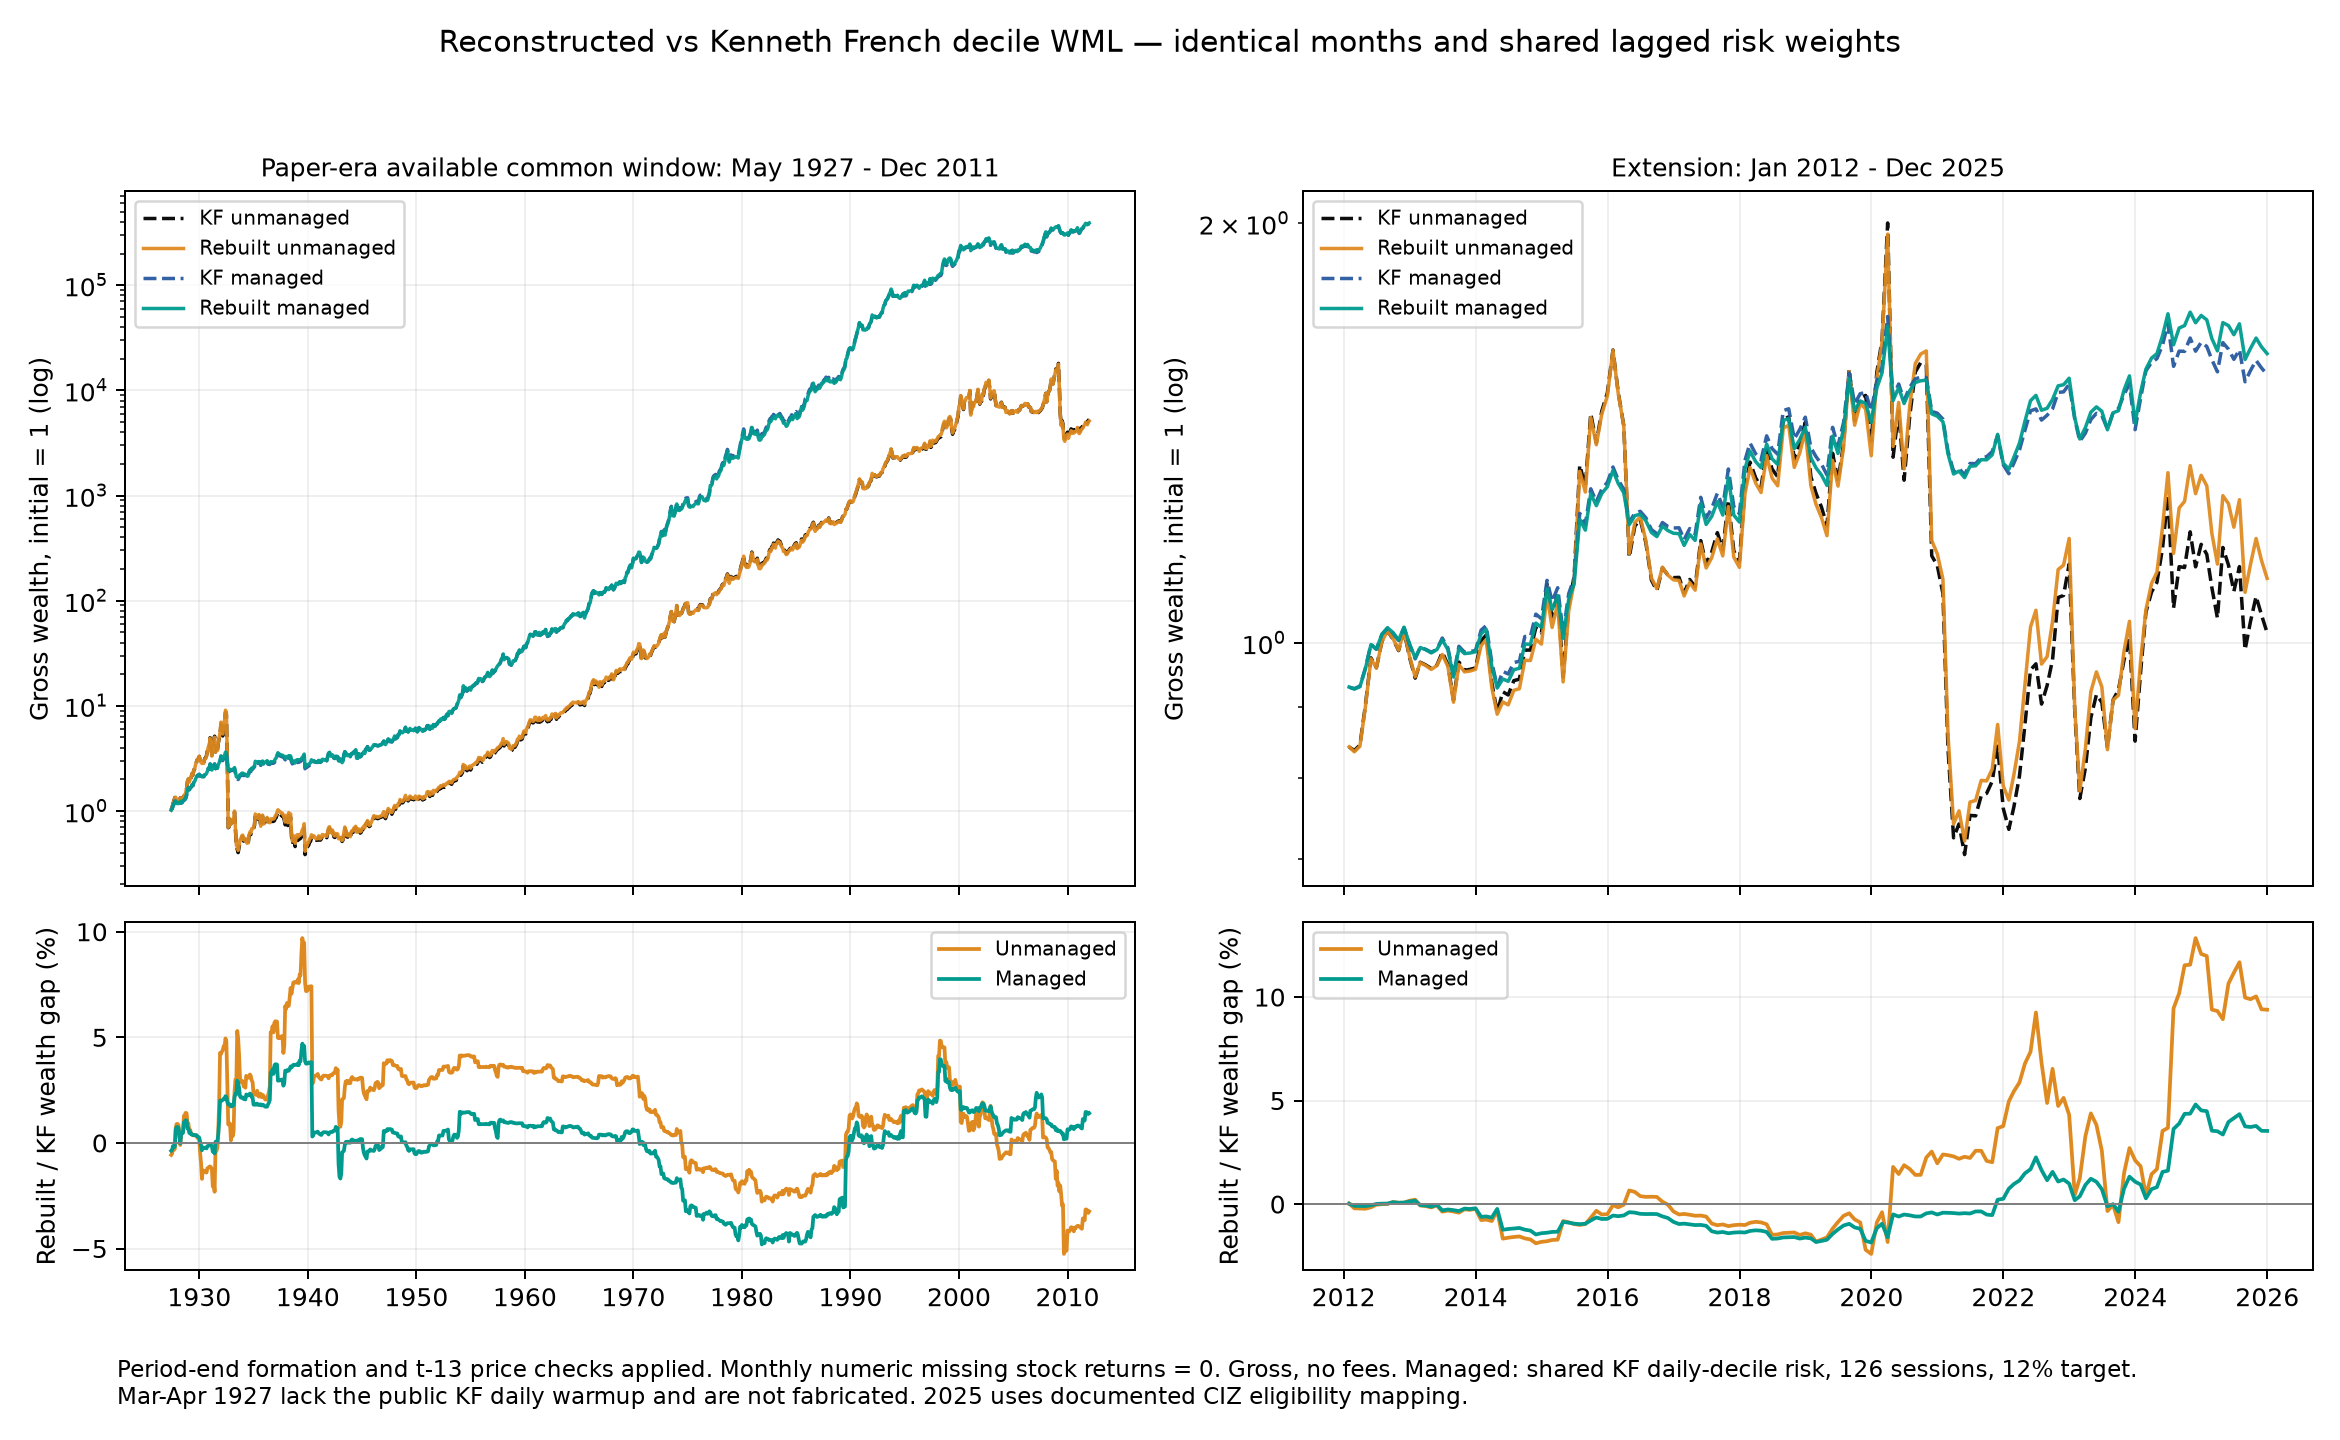

In [5]:
returns = pd.DataFrame({
    "KF unmanaged": kf_monthly.reindex(months),
    "Stock reference unmanaged": reference_monthly.WML.reindex(months),
    "KF managed (shared KF risk)": kf_monthly.reindex(months) * kf_weights,
    "Stock reference managed (shared KF risk)": reference_monthly.WML.reindex(months) * kf_weights,
})
rows = []
for label, (start, end) in WINDOWS.items():
    block = returns.reindex(pd.period_range(start, end, freq="M"))
    assert block.notna().all().all(), f"Incomplete reference window: {label}"
    for strategy in block:
        rows.append({"window": label, "start": start, "end": end, "months": len(block),
                     "strategy": strategy, **performance_metrics(block[strategy]).to_dict()})
complete_results = pd.DataFrame(rows)
display_metrics(complete_results)
shared_reference = read_monthly_csv(REFERENCE / "shared_risk_weights.csv").iloc[:, 0]
np.testing.assert_allclose(kf_weights, shared_reference.reindex(months), equal_nan=True, atol=1e-12)
display(Image(filename=str(QUALITY / "aligned_wml_comparison.png")))

## 6. Stock trading costs and residuals against KF

Stock-reference accounts use 10bp per dollar of absolute stock trades and zero financing. Trades compare new targets with prior return-drifted positions, including entries and exits. Fees are funded by solving post-cost NAV and target positions jointly. Monthly total returns drive P&L, ex-distribution returns drive stock drift, and distributions enter cash as a monthly approximation. No terminal liquidation fee is imposed. KF stock costs are unavailable without its holdings; factor-weight changes are not substituted for total stock turnover.

These complete stock accounts retain the published-return terminal-value qualification. They are not the incomplete current DM-aligned account. Short borrow fees, rebates, capacity, market impact and actual delayed cash settlement are not identified.

Residuals are reported separately: high correlation does not establish exact replication. Current DM comparisons use paired known months only for return-error diagnostics, never for a compounded performance path.

**August 1935 finding.** American Express has a July CIZ last-available quote dated July 29 (337.50), not a confirmed month-end price; its aggregate flags are `LA / R / R1`. Legacy July price and return are missing. The current positive-capitalization screen nevertheless admits it to the August loser leg with 36.47% weight. July is skipped for ranking, but its market equity still determines August weights.

CIZ allocates +145.45% to July and −51.85% to August; their compounded +18.18% equals the legacy August return. This is a price-date/return-period interpretation difference, not evidence that an arbitrary price should be corrected, and not a delisting or zero-fill event.

Holding other memberships fixed and omitting this stock gives WML −18.28% versus KF −18.32%. A general period-end formation-value screen with recalculated NYSE cutoffs gives −18.41%. These diagnostics locate the dominant mechanism; they do not establish KF's exact internal screen or a validated full-sample correction. A general rule must be validated before regenerating breakpoints, daily membership data and account results. [CRSP date flags](https://www.crsp.org/wp-content/uploads/appendix/FlagType_AG.html), [completeness](https://www.crsp.org/wp-content/uploads/appendix/FlagType_CF.html), [sub-flags](https://www.crsp.org/wp-content/uploads/appendix/FlagType_CG.html).


In [6]:
print("Table 6.1 — Current screened stock-reference NET performance and costs")
print("Shared KF risk, 10bp per dollar traded, financing 0. Reference valuations retain terminal uncertainty.")
cost_rows = []
for label, (start, end) in WINDOWS.items():
    index = pd.period_range(start, end, freq="M")
    for strategy, weights in [("unmanaged", pd.Series(1., index=index)),
                              ("managed_shared_KF_risk", kf_weights.reindex(index))]:
        ledger, trades = wml_build.backtest(weights, return_policy="published_reference",
                                           transaction_cost_bps=10., financing_cost_bps=0.)
        complete = bool(ledger.net_return.notna().all() and ledger.state.eq("ok").all())
        assert complete
        row = {"window": label, "strategy": strategy, "complete": complete,
               "evaluated_months": len(ledger), "mean_monthly_turnover": ledger.turnover.mean(),
               "annual_trading_cost": 12 * ledger.transaction_cost.mean(),
               **performance_metrics(ledger.net_return).to_dict()}
        cost_rows.append(row)
stock_costs = pd.DataFrame(cost_rows)
net_results = stock_costs
display_metrics(net_results)
print("The src account uses attached delisting evidence for settlement; prior reference fee ledgers without that evidence are not reused.")
print("Table 6.2 — Monthly reconstruction errors before and after formation-quality checks")
print("Errors in basis points; correlation unitless. Updated rule covers formation and t-13 price dates.")
reference_errors = pd.read_csv(QUALITY / "reconstruction_errors.csv")
display(reference_errors)
print("Table 6.3 — Current DM monthly WML versus KF: known paired months only")
paired_rows = []
for label,(a,b) in WINDOWS.items():
    block=native.loc[a:b]; pair=block.dropna(); e=pair.reconstructed_DM_unmanaged-pair.KF_unmanaged
    paired_rows.append({"window":label,"calendar_months":len(block),"known_paired_months":len(pair),
      "correlation":pair.corr().iloc[0,1],"MAE_bps":e.abs().mean()*10000,"RMSE_bps":np.sqrt(e.pow(2).mean())*10000})
current_errors=pd.DataFrame(paired_rows);display(current_errors)
print("Table 6.4 — Largest monthly residuals AFTER formation-quality checks")
r=reference.reconstructed_unmanaged-reference.KF_unmanaged
residuals=pd.DataFrame({"KF":reference.KF_unmanaged,"Rebuilt":reference.reconstructed_unmanaged,"difference_pp":100*r,"absolute_error_bps":10000*r.abs()})
display(residuals.loc[r.abs().nlargest(5).index])
print("Table 6.5 — August 1935: diagnostic attribution and current full-sample screened result")
august_audit=pd.read_csv(AUDIT / "reconciliation.csv");display(august_audit)
display(reference.loc[[pd.Period("1935-08")]])
print("Table 6.6 — Excluded formation records (stock-month counts, not permanent security exclusions)")
quality_run=json.loads((QUALITY / "run.json").read_text());display(pd.Series(quality_run["counts"],name="Count").to_frame())


Table 6.1 — Current screened stock-reference NET performance and costs
Shared KF risk, 10bp per dollar traded, financing 0. Reference valuations retain terminal uncertainty.


,window,strategy,complete,evaluated_months,mean_monthly_turnover,annual_trading_cost,Annualized Mean Return,Annualized Volatility,Sharpe (rf=0),CAGR,Maximum Drawdown,Terminal Wealth
0,paper_available_common,unmanaged,True,1016,1.536254,0.018435,13.00%,27.45%,0.474,8.59%,-96.22%,1071.758178
1,paper_available_common,managed_shared_KF_risk,True,1016,1.352080,0.016225,15.07%,16.74%,0.900,14.55%,-43.91%,98744.011592
2,extension_disjoint,unmanaged,True,168,1.489615,0.017875,2.84%,27.12%,0.105,-1.02%,-64.14%,0.865812
3,extension_disjoint,managed_shared_KF_risk,True,168,0.752407,0.009029,3.22%,11.92%,0.270,2.54%,-22.54%,1.420802


The src account uses attached delisting evidence for settlement; prior reference fee ledgers without that evidence are not reused.
Table 6.2 — Monthly reconstruction errors before and after formation-quality checks
Errors in basis points; correlation unitless. Updated rule covers formation and t-13 price dates.


,window,series,months,correlation,MAE_bps,RMSE_bps
0,paper_available_common,old_unmanaged,1016,0.993034,19.381913,93.425443
1,paper_available_common,quality_screened_unmanaged,1016,0.999150,13.905970,32.705354
2,extension_disjoint,old_unmanaged,168,0.994158,47.214176,84.666351
3,extension_disjoint,quality_screened_unmanaged,168,0.994141,47.434354,84.778615


Table 6.3 — Current DM monthly WML versus KF: known paired months only


,window,calendar_months,known_paired_months,correlation,MAE_bps,RMSE_bps
0,paper_available_common,1016,566,0.998689,14.833871,38.125600
1,extension_disjoint,168,109,0.996147,38.455004,70.297977


... (3 outputs left out)

,case,P1,P10,WML,WML_minus_KF_bps
0,Published-return reconstruction,-0.050696,0.035056,0.085752,2689.520256
1,"Diagnostic: omit one stock, other memberships ...",0.217812,0.035056,-0.182755,4.445749
2,"Diagnostic: period-end formation values, NYSE ...",0.219154,0.035056,-0.184098,-8.976521
3,KF published deciles,0.217800,0.034600,-0.183200,0.000000


,KF_unmanaged,old_unmanaged,reconstructed_unmanaged,KF_managed_shared_risk,quality_screened_managed_shared_risk
Unnamed: 0,,,,,
1935-08,-0.1832,0.085752,-0.18323,-0.051335,-0.051344


Table 6.6 — Excluded formation records (stock-month counts, not permanent security exclusions)


,Count
all_deciles_removed_stock_months,2987
WML_removed_stock_months,1062
WML_removed_distinct_stocks,827
WML_affected_holding_months,395
all_quality_removed_stock_months,6080
all_quality_removed_prior_WML_stock_months,2117
all_quality_removed_prior_WML_stocks,1361


## 7. Essential validation, conclusions and limits

**Validation retained:** normalized leg weights; formation precedes holding; eligible historical/mapped classifications; ranking and required prices; delisting counted once; independently reconstructed monthly series; one-month raw-daily integration check; 126-day weights; shared-risk identity; future-data invariance; and explicit missing coverage. The library test suite additionally covers fees funded from NAV, entries/exits, return drift, missing-terminal protection and the 200-day boundary.

**Results:** In the complete available paper-era reference, volatility management improves mean return, Sharpe and drawdown for both KF and reconstructed WML. In 2012–2025 it improves Sharpe, drawdown and compounded growth, while arithmetic mean return is slightly lower. These statements concern the labelled complete reference; independent own-stock-risk replication is still incomplete.

**Material limits:** Current public KF daily history leaves 30 sessions missing for the March 1927 forecast and three for April; the first complete forecast is May. CRSP individual-stock history begins December 1925, insufficient for full-rule 1926 monthly momentum formation. Unknown terminal values still prevent the current independent backtest from covering all months. Formation and t-13 price/date checks are now applied across the full sample: August 1935 WML is -18.323% versus KF -18.320%; historical MAE is 13.91bp. Extension MAE remains approximately 47.43bp. Independent daily inputs are rebuilt; multi-session/terminal uncertainty still prevents complete stock-risk evaluation. Matching the published 1963–2011 snapshot does not prove identical historical CRSP release vintages. These limits are not removed by ordinary-return zero filling.

In [7]:
changed = kf_daily.copy()
cutoff = pd.Timestamp("2009-02-01")
changed.loc[changed.index >= cutoff] *= 1.2
changed_weights = risk_weights(changed, months)
np.testing.assert_allclose(changed_weights.loc[:"2009-02"], kf_weights.loc[:"2009-02"], equal_nan=True)
assert kf_weights.loc["1927-03":"1927-04"].isna().all()
assert kf_weights.loc["1927-05":"2025-12"].notna().all()
assert not holdings.loc[holdings.mthdelflg.isin(["G","M","V"]) & ~holdings.payoff_complete, "current_return"].notna().any()
assert current_run["zero_rule_is_DM_official"] is False
print("All construction, return, risk, causality and coverage checks passed.")

if API_ARTIFACT.exists():
    restored = load_build(API_ARTIFACT)
    pd.testing.assert_frame_equal(restored.monthly_dm, wml_build.monthly_dm)
    pd.testing.assert_frame_equal(restored.monthly_reference, wml_build.monthly_reference)
    pd.testing.assert_frame_equal(restored.daily, wml_build.daily)
    assert restored.audit["membership_digest"] == wml_build.audit["membership_digest"]
else:
    save_build(wml_build, API_ARTIFACT)
print("Notebook05 build artifact:", API_ARTIFACT)
REPORT.mkdir(parents=True, exist_ok=True)
for name, frame in {"complete_reference_metrics": complete_results,
                    "current_DM_paired_return_errors": current_errors,
                    "current_DM_coverage": coverage,
                    "reference_stock_cost_metrics": stock_costs,
                    "reference_turnover_and_costs": net_results,
                    "august_1935_attribution": august_audit, "screened_reconstruction_errors":reference_errors}.items():
    path = REPORT / f"{name}.parquet"
    if path.exists(): pd.testing.assert_frame_equal(pd.read_parquet(path), frame)
    else: frame.to_parquet(path, index=False)
report_manifest = {
    "current_code_sha256": wml_build.provenance["code_sha256"], "windows": WINDOWS, "ordinary_missing_rule": "zero", "terminal_rule": "known DM payoff once; unknown retained",
    "risk_window": WINDOW, "days_per_month": DAYS_PER_MONTH, "annual_target": TARGET_VOL,
    "complete_results_scope": "published-return stock reference with shared KF risk; current independent DM results withheld",
    "input_sha256": {str(p.relative_to(ROOT)): sha256(p) for p in [
        API_ARTIFACT / "manifest.json", QUALITY / "run.json", AUDIT / "summary.json", CACHE / "cache_manifest.json", CURRENT / "run.json", CURRENT / "monthly_comparison.csv",
        CURRENT / "daily_WML_zero_regular_DM.parquet", REFERENCE / "run.json",
        ROOT / "data/raw/02_kf_momentum_deciles_daily_vw.parquet",
        ROOT / "data/raw/02_kf_momentum_deciles_monthly_vw.parquet"]},
}
path = REPORT / "run.json"
if path.exists(): assert json.loads(path.read_text()) == json.loads(json.dumps(report_manifest))
else: path.write_text(json.dumps(report_manifest, indent=2) + "\n")
print("Reproducible report:", REPORT)

All construction, return, risk, causality and coverage checks passed.


Notebook05 build artifact: /Users/guochuanchu/Downloads/momentum-risk-project/data/processed/wml_current_v1_20261031
Reproducible report: /Users/guochuanchu/Downloads/momentum-risk-project/outputs/03_wml/report


## 8. Reproduce and use in Notebook 05

The single current implementation is `momentum_risk_project.wml_pipeline`. This notebook rebuilds from the frozen source and validates all monthly and daily WML series against the previous verified calculation. It saves a fingerprinted private build for downstream use.

```bash
uv run python -m momentum_risk_project.wml_pipeline \
  --cache-dir data/raw/03_stock_full_20261031 \
  --daily-cache-dir data/raw/03_quality_daily_20261031 \
  --output-dir data/processed/wml_current_new
uv run pytest tests/ -q
```

In Notebook 05, `load_build(...)` restores holdings, breakpoints, strict DM/reference monthly returns and checked daily returns. `build.backtest(weights, return_policy="dm", transaction_cost_bps=10)` returns both the monthly account and actual stock trades. Policy is mandatory; missing terminal values stop strict account evaluation. `published_reference` is a separately named conditional valuation, not an automatic fallback. `build.targets(weights)` exposes signed stock target weights.

Each backtest call starts with NAV one and no existing positions; use one continuous run and slice the resulting ledger when portfolio continuity across evaluation windows is required. Data and delisting uncertainty remain visible. See `WML_PIPELINE.md` for the API and schema. Notebook 02 remains identical to GitHub main.
